In [ ]:
# ============================================================================
# LOAD ONLY -- RUN FIRST.  Loads every per-site bed ONCE into m_hcg / m_gch.
# Plotting/formatting lives in each plotting cell below (self-contained).
#   NOTE: genome-wide GCH is large (~200M sites); give the kernel tens of GB RAM.
# ============================================================================
suppressPackageStartupMessages(library(data.table))

PB_GCH <- "/gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/gm_sc_new/pseudobulk_methylation/gm_pseudobulk_merged.GCH.6plus2.bed.gz"
BK_GCH <- "/scratch/jmj7858/scnomehic/bulk_gm/pipeline/06b.methylation_merged/bulk_GM12878_merged.cyt.filtered.sort.GCH.6plus2.bed.gz"
PB_HCG <- "/gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/gm_sc_new/pseudobulk_methylation/gm_pseudobulk_merged.HCG.6plus2.bed.gz"
BK_HCG <- "/scratch/jmj7858/scnomehic/bulk_gm/pipeline/06b.methylation_merged/bulk_GM12878_merged.cyt.filtered.sort.HCG.6plus2.bed.gz"
FIGDIR <- "/gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/gm_sc_new/figures"
MINCT  <- 10

# read 6plus2 bed: skip 'track' lines; cols chr,start,end,name,score,strand,rate%,cov
read6 <- function(p) {
  d <- fread(cmd = paste("zcat", p, "| grep -v '^track'"),
             header = FALSE, select = c(1,2,3,7,8),
             col.names = c("chr","start","end","rate","cov"))
  d[, .(chr, start, end, m = rate/100 * cov, cov)]
}
load_ctx <- function(pb_path, bk_path) {
  pb <- read6(pb_path); setnames(pb, c("chr","start","end","m_pb","cov_pb"))
  bk <- read6(bk_path); setnames(bk, c("chr","start","end","m_bk","cov_bk"))
  pb <- unique(pb, by = c("chr","start","end")); bk <- unique(bk, by = c("chr","start","end"))
  merge(pb, bk, by = c("chr","start","end"), all = TRUE)
}
m_hcg <- load_ctx(PB_HCG, BK_HCG)
m_gch <- load_ctx(PB_GCH, BK_GCH)
cat(sprintf("loaded: m_hcg = %s sites, m_gch = %s sites\n",
            format(nrow(m_hcg), big.mark=","), format(nrow(m_gch), big.mark=",")))


n = 9,779,549   Pearson r = 0.932   Spearman rho = 0.918


pdf 
  2

wrote /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/gm_sc_new/figures/newbulk_locus_HCG_methylation_minCT_10.pdf 


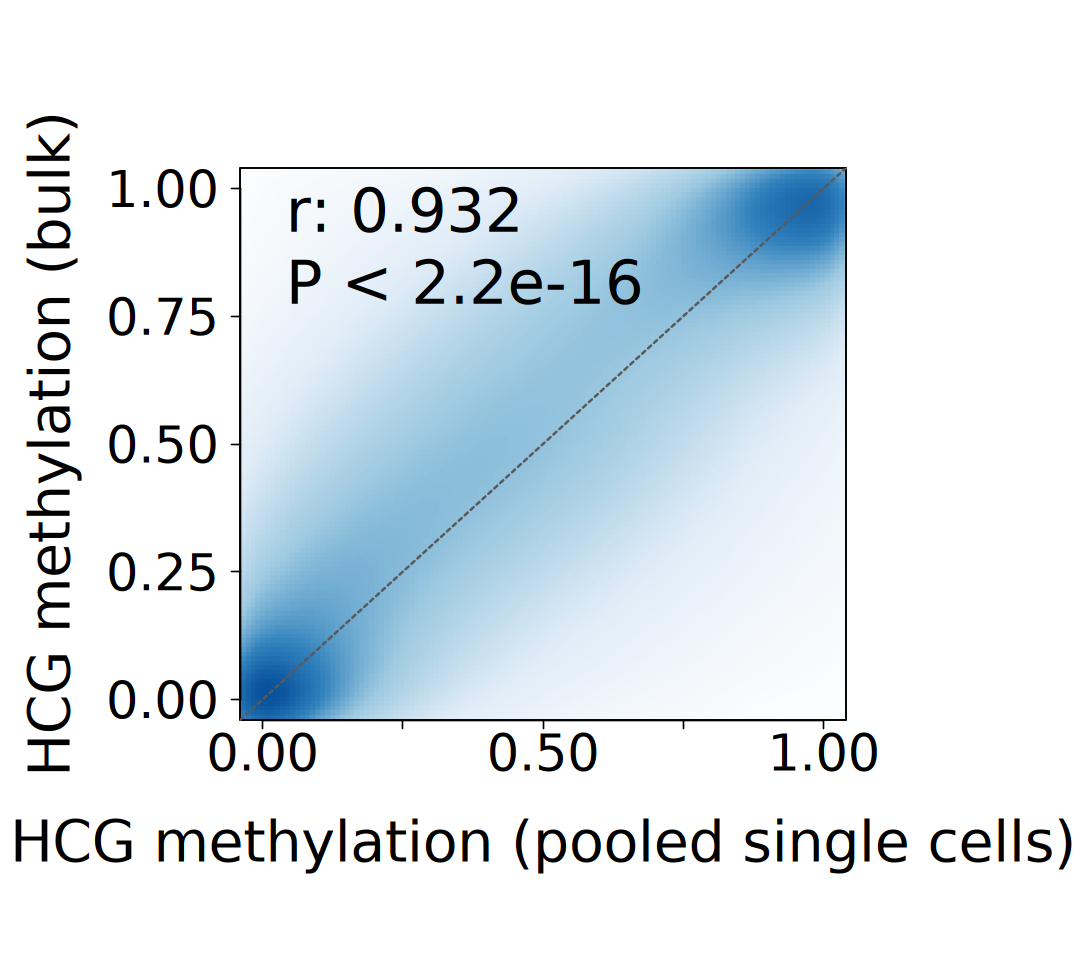

In [60]:
# Locus-level HCG (CpG methylation): pooled single cells vs from-scratch bulk, minCT >= 10.
stopifnot(exists("m_hcg"))
t <- MINCT
s <- m_hcg[cov_pb >= t & cov_bk >= t]
x <- s$m_pb / s$cov_pb
y <- s$m_bk / s$cov_bk
r_p <- cor(x, y)
r_s <- cor(x, y, method = "spearman")
cat(sprintf("n = %s   Pearson r = %.3f   Spearman rho = %.3f\n",
            format(nrow(s), big.mark = ","), r_p, r_s))

stat_choice <- "pearson"   # annotation: "pearson" or "spearman"
annot <- if (stat_choice == "spearman") sprintf("rho: %.3f\nP < 2.2e-16", r_s) else sprintf("r: %.3f\nP < 2.2e-16", r_p)

bpalette <- colorRampPalette(c("white", "#deebf7", "#9ecae1", "#3182bd", "#08519c"))
draw_one <- function() {
  par(mar = c(10, 10, 7, 10), mgp = c(6, 1.2, 0),
      cex.lab = 2.5, cex.axis = 2.5, family = "sans", tcl = -0.35, las = 1)
  smoothScatter(x, y, xlim = c(0, 1), ylim = c(0, 1), nrpoints = 0,
                xlab = "", ylab = "", main = "", colramp = bpalette, axes = FALSE)
  axis(1, at = seq(0, 1, by = 0.25), lwd = 1, mgp = c(3, 1.2, 0))
  axis(2, at = seq(0, 1, by = 0.25), lwd = 1, las = 1, mgp = c(3.5, 0.9, 0))
  mtext("HCG methylation (pooled single cells)", side = 1, line = 5.0, cex = 2.8)
  mtext("HCG methylation (bulk)", side = 2, line = 7,   cex = 2.8, las = 0)
  box(lwd = 1)
  abline(0, 1, lty = 2, lwd = 1.5, col = "grey35")
  text(0.02, 0.85, annot, pos = 4, cex = 3, font = 2)
}
out_pdf <- file.path(FIGDIR, "newbulk_locus_HCG_methylation_minCT_10.pdf")
fig_w <- 9.05; fig_h <- 8
pdf(out_pdf, width = fig_w, height = fig_h, useDingbats = FALSE, family = "Helvetica"); draw_one(); dev.off()
cat("wrote", out_pdf, "\n")
options(repr.plot.width = fig_w, repr.plot.height = fig_h); draw_one()


In [ ]:
# Locus-level GCH (GpC accessibility): pooled single cells vs from-scratch bulk.
# 2x2 grid over per-site coverage thresholds minCT = 5, 10, 15, 20 (both sides).
stopifnot(exists("m_gch"))
thr <- c(5, 10, 15, 20)
locus_xy <- function(t) {
  s <- m_gch[cov_pb >= t & cov_bk >= t]
  list(x = s$m_pb / s$cov_pb, y = s$m_bk / s$cov_bk, n = nrow(s))
}
for (t in thr) { z <- locus_xy(t)
  cat(sprintf("GCH locus  minCT >= %2d   n = %s   Pearson r = %.3f   Spearman rho = %.3f\n",
              t, format(z$n, big.mark = ","),
              cor(z$x, z$y), cor(z$x, z$y, method = "spearman"))) }

stat_choice <- "pearson"   # annotation: "pearson" or "spearman"
bpalette <- colorRampPalette(c("white", "#deebf7", "#9ecae1", "#3182bd", "#08519c"))
draw_grid <- function() {
  par(mfrow = c(2,2), mar = c(7.0, 7.5, 4.0, 2.0), mgp = c(4, 0.8, 0),
      cex.main = 1.7, family = "sans", tcl = -0.3, las = 1)
  for (t in thr) {
    z <- locus_xy(t)
    r_p <- cor(z$x, z$y); r_s <- cor(z$x, z$y, method = "spearman")
    annot <- if (stat_choice == "spearman") sprintf("rho: %.3f\nP < 2.2e-16", r_s) else sprintf("r: %.3f\nP < 2.2e-16", r_p)
    smoothScatter(z$x, z$y, xlim = c(0,1), ylim = c(0,1), nrpoints = 0,
                  xlab = "", ylab = "",
                  main = sprintf("locus  minCT >= %d   (n = %s)", t, format(z$n, big.mark = ",")),
                  colramp = bpalette, axes = FALSE)
    axis(1, at = seq(0,1,0.25), lwd = 1, mgp = c(3, 0.8, 0), cex.axis = 1.5)
    axis(2, at = seq(0,1,0.25), lwd = 1, las = 1, mgp = c(3, 0.8, 0), cex.axis = 1.5)
    mtext("GCH accessibility (pooled SC)", side = 1, line = 3.2, cex = 1.7)
    mtext("GCH accessibility (bulk)",      side = 2, line = 4.0, cex = 1.7, las = 0)
    box(lwd = 1)
    abline(0, 1, lty = 2, lwd = 1.5, col = "grey35")
    text(0.02, 0.92, annot, pos = 4, cex = 1.8, font = 2)
  }
}
out_pdf <- file.path(FIGDIR, "newbulk_locus_GCH_accessibility_minCT_5_10_15_20.pdf")
fig_w <- 14; fig_h <- 14
pdf(out_pdf, width = fig_w, height = fig_h, useDingbats = FALSE, family = "Helvetica"); draw_grid(); dev.off()
cat("wrote", out_pdf, "\n")
options(repr.plot.width = fig_w, repr.plot.height = fig_h); draw_grid()


GCH 250kb  minCT >=  10   n_bins = 11,616   Pearson r = 0.574
GCH 250kb  minCT >=  20   n_bins = 11,552   Pearson r = 0.689
GCH 250kb  minCT >=  50   n_bins = 4,292   Pearson r = 0.516
GCH 250kb  minCT >= 100   n_bins = 244   Pearson r = 0.759


pdf 
  2

wrote /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/gm_sc_new/figures/newbulk_acc_250kb_GCH_minCT_10_20_50_100.pdf 


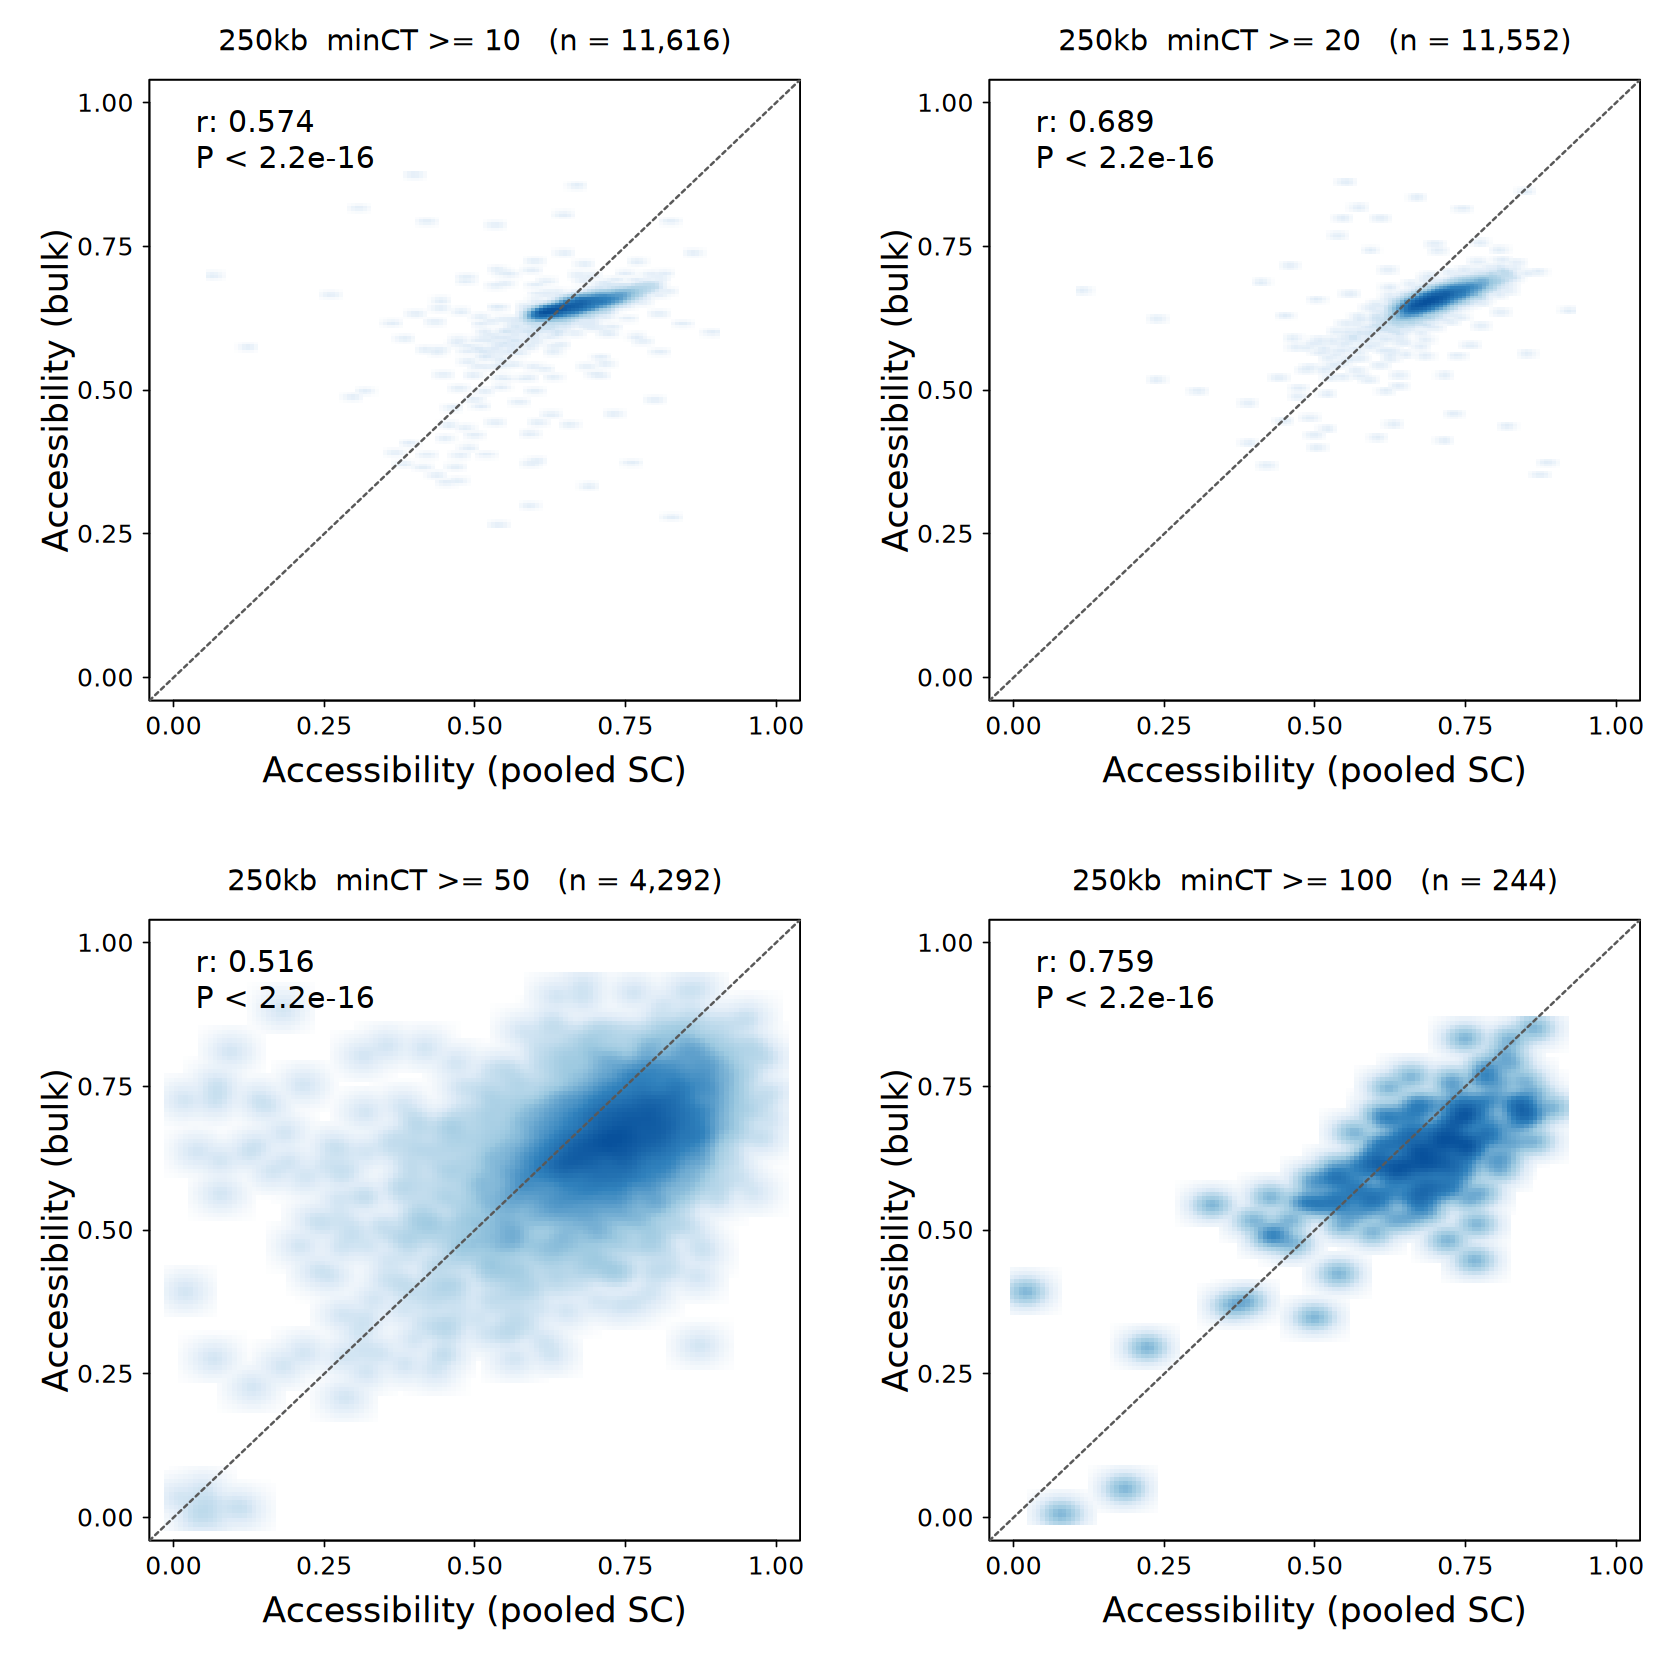

In [62]:
# 250kb-bin GCH accessibility: 2x2 grid at minCT = 10, 20, 50, 100 (per-site
# coverage, both sides) -> aggregate into 250kb bins -> compare. Same look, scaled.
stopifnot(exists("m_gch"))
BIN <- 250000
thr <- c(10, 20, 50, 100)
bin250 <- function(t) {
  s <- m_gch[cov_pb >= t & cov_bk >= t]
  s[, .(m_pb = sum(m_pb), cov_pb = sum(cov_pb),
        m_bk = sum(m_bk), cov_bk = sum(cov_bk)),
    by = .(chr, bin = start %/% BIN)][cov_pb > 0 & cov_bk > 0][
    , .(pseudobulk = m_pb / cov_pb, bulk = m_bk / cov_bk)]
}
for (t in thr) { b <- bin250(t)
  cat(sprintf("GCH 250kb  minCT >= %3d   n_bins = %s   Pearson r = %.3f\n",
              t, format(nrow(b), big.mark = ","), cor(b$pseudobulk, b$bulk))) }

bpalette <- colorRampPalette(c("white", "#deebf7", "#9ecae1", "#3182bd", "#08519c"))
draw_grid <- function() {
  par(mfrow = c(2,2), mar = c(7.0, 7.5, 4.0, 2.0), mgp = c(4, 0.8, 0),
      cex.main = 1.7, family = "sans", tcl = -0.3, las = 1)
  for (t in thr) {
    b <- bin250(t)
    smoothScatter(b$pseudobulk, b$bulk, xlim = c(0,1), ylim = c(0,1), nrpoints = 0,
                  xlab = "", ylab = "",
                  main = sprintf("250kb  minCT >= %d   (n = %s)", t, format(nrow(b), big.mark = ",")),
                  colramp = bpalette, axes = FALSE)
    axis(1, at = seq(0,1,0.25), lwd = 1, mgp = c(3, 0.8, 0), cex.axis = 1.5)
    axis(2, at = seq(0,1,0.25), lwd = 1, las = 1, mgp = c(3, 0.8, 0), cex.axis = 1.5)
    mtext("Accessibility (pooled SC)", side = 1, line = 3.2, cex = 1.7)
    mtext("Accessibility (bulk)",      side = 2, line = 4.0, cex = 1.7, las = 0)
    box(lwd = 1)
    abline(0, 1, lty = 2, lwd = 1.5, col = "grey35")
    text(0.02, 0.92, sprintf("r: %.3f\nP < 2.2e-16", cor(b$pseudobulk, b$bulk)),
         pos = 4, cex = 1.8, font = 2)
  }
}
out_pdf <- file.path(FIGDIR, "newbulk_acc_250kb_GCH_minCT_10_20_50_100.pdf")
fig_w <- 14; fig_h <- 14
pdf(out_pdf, width = fig_w, height = fig_h, useDingbats = FALSE, family = "Helvetica"); draw_grid(); dev.off()
cat("wrote", out_pdf, "\n")
options(repr.plot.width = fig_w, repr.plot.height = fig_h); draw_grid()


In [ ]:
# 250kb-bin GCH accessibility, QUANTILE-NORMALIZED: 2x2 grid at minCT = 10, 20, 50, 100.
# Per panel: per-site cov >= t (both sides) -> 250kb bins -> quantile-normalize the
# pseudobulk/bulk bin levels -> compare. Same inline large-font style, scaled.
stopifnot(exists("m_gch"))
BIN <- 250000
thr <- c(10, 20, 50, 100)
bin250 <- function(t) {
  s <- m_gch[cov_pb >= t & cov_bk >= t]
  s[, .(m_pb = sum(m_pb), cov_pb = sum(cov_pb),
        m_bk = sum(m_bk), cov_bk = sum(cov_bk)),
    by = .(chr, bin = start %/% BIN)][cov_pb > 0 & cov_bk > 0][
    , .(pseudobulk = m_pb / cov_pb, bulk = m_bk / cov_bk)]
}
quantile_normalize <- function(matrix_data) {
  n_rows <- nrow(matrix_data); n_cols <- ncol(matrix_data)
  max_non_na <- max(colSums(!is.na(matrix_data)))
  sorted_matrix <- matrix(NA_real_, nrow = max_non_na, ncol = n_cols)
  for (i in seq_len(n_cols)) { v <- matrix_data[, i]; v <- sort(v[!is.na(v)])
    sorted_matrix[seq_along(v), i] <- v }
  row_means <- rowMeans(sorted_matrix, na.rm = TRUE)
  out <- matrix(NA_real_, nrow = n_rows, ncol = n_cols, dimnames = dimnames(matrix_data))
  for (i in seq_len(n_cols)) { v <- matrix_data[, i]; na <- is.na(v)
    out[!na, i] <- row_means[rank(v[!na], ties.method = "average")] }
  out
}
qn_bins <- function(t) {
  b  <- bin250(t)
  qn <- quantile_normalize(as.matrix(b[, .(pseudobulk, bulk)]))
  list(x = qn[, 1], y = qn[, 2], n = nrow(b))
}
for (t in thr) { z <- qn_bins(t)
  cat(sprintf("GCH 250kb QN  minCT >= %3d   n_bins = %s   Pearson r = %.3f\n",
              t, format(z$n, big.mark = ","), cor(z$x, z$y))) }

bpalette <- colorRampPalette(c("white", "#deebf7", "#9ecae1", "#3182bd", "#08519c"))
draw_grid <- function() {
  par(mfrow = c(2,2), mar = c(7.0, 7.5, 4.0, 2.0), mgp = c(4, 0.8, 0),
      cex.main = 1.7, family = "sans", tcl = -0.3, las = 1)
  for (t in thr) {
    z <- qn_bins(t)
    smoothScatter(z$x, z$y, xlim = c(0,1), ylim = c(0,1), nrpoints = 0,
                  xlab = "", ylab = "",
                  main = sprintf("250kb QN  minCT >= %d   (n = %s)", t, format(z$n, big.mark = ",")),
                  colramp = bpalette, axes = FALSE)
    axis(1, at = seq(0,1,0.25), lwd = 1, mgp = c(3, 0.8, 0), cex.axis = 1.5)
    axis(2, at = seq(0,1,0.25), lwd = 1, las = 1, mgp = c(3, 0.8, 0), cex.axis = 1.5)
    mtext("Accessibility (pooled SC, QN)", side = 1, line = 3.2, cex = 1.7)
    mtext("Accessibility (bulk, QN)",      side = 2, line = 4.0, cex = 1.7, las = 0)
    box(lwd = 1)
    abline(0, 1, lty = 2, lwd = 1.5, col = "grey35")
    text(0.02, 0.92, sprintf("r: %.3f\nP < 2.2e-16", cor(z$x, z$y)),
         pos = 4, cex = 1.8, font = 2)
  }
}
out_pdf <- file.path(FIGDIR, "newbulk_acc_250kb_GCH_minCT_10_20_50_100_quantileNorm.pdf")
fig_w <- 14; fig_h <- 14
pdf(out_pdf, width = fig_w, height = fig_h, useDingbats = FALSE, family = "Helvetica"); draw_grid(); dev.off()
cat("wrote", out_pdf, "\n")
options(repr.plot.width = fig_w, repr.plot.height = fig_h); draw_grid()


n = 11,670   Pearson r = 0.622   Spearman rho = 0.756


pdf 
  2

wrote /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/gm_sc_new/figures/newbulk_acc_250kb_GCH.pdf 


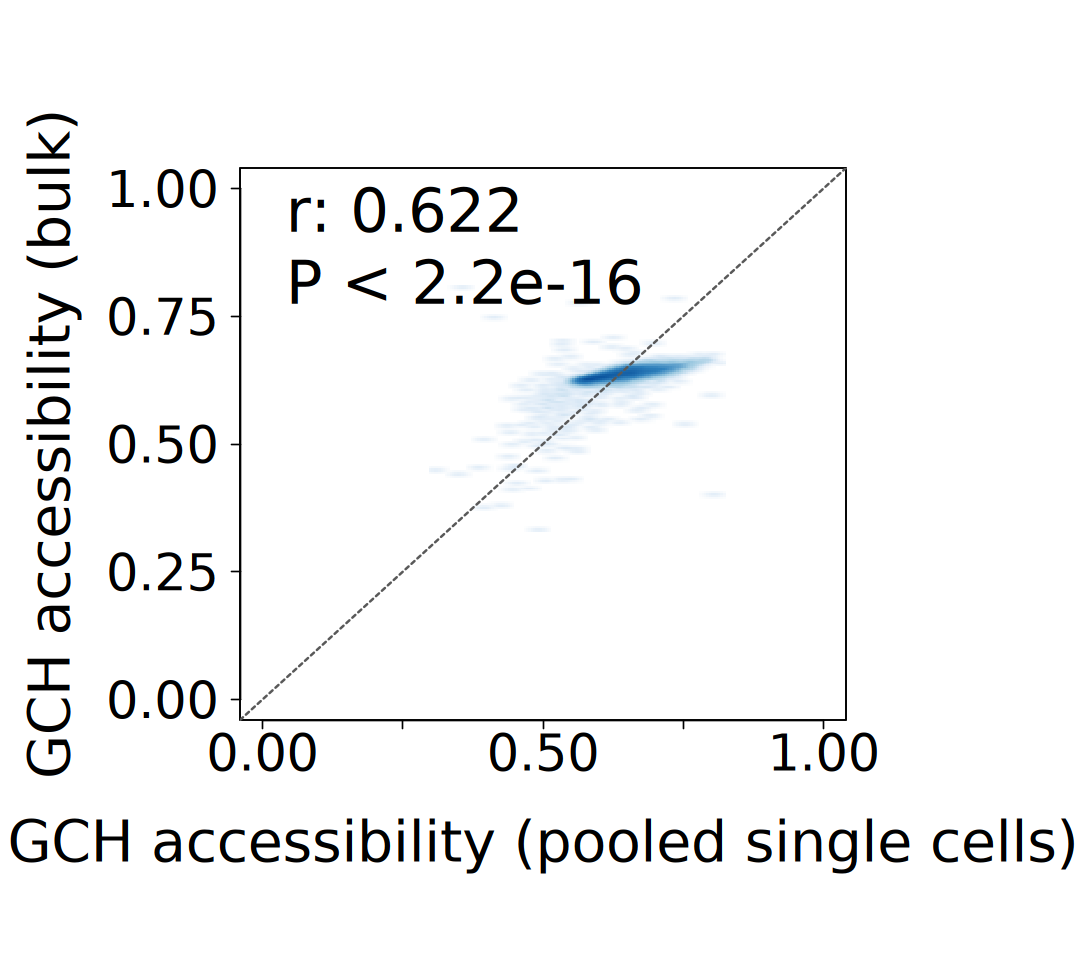

In [63]:
# 250kb-bin GCH accessibility (raw): pooled single cells vs from-scratch bulk. Builds `m`.
stopifnot(exists("m_gch"))
BIN <- 250000
m <- m_gch[, .(m_pb = sum(m_pb, na.rm = TRUE), cov_pb = sum(cov_pb, na.rm = TRUE),
            m_bk = sum(m_bk, na.rm = TRUE), cov_bk = sum(cov_bk, na.rm = TRUE)),
        by = .(chr, bin = start %/% BIN)][cov_pb > 0 & cov_bk > 0][
        , .(chr, bin, pseudobulk = m_pb / cov_pb, bulk = m_bk / cov_bk)]
x <- m$pseudobulk; y <- m$bulk
r_p <- cor(x, y)
r_s <- cor(x, y, method = "spearman")
cat(sprintf("n = %s   Pearson r = %.3f   Spearman rho = %.3f\n",
            format(nrow(m), big.mark = ","), r_p, r_s))

stat_choice <- "pearson"   # annotation: "pearson" or "spearman"
annot <- if (stat_choice == "spearman") sprintf("rho: %.3f\nP < 2.2e-16", r_s) else sprintf("r: %.3f\nP < 2.2e-16", r_p)

bpalette <- colorRampPalette(c("white", "#deebf7", "#9ecae1", "#3182bd", "#08519c"))
draw_one <- function() {
  par(mar = c(10, 10, 7, 10), mgp = c(6, 1.2, 0),
      cex.lab = 2.5, cex.axis = 2.5, family = "sans", tcl = -0.35, las = 1)
  smoothScatter(x, y, xlim = c(0, 1), ylim = c(0, 1), nrpoints = 0,
                xlab = "", ylab = "", main = "", colramp = bpalette, axes = FALSE)
  axis(1, at = seq(0, 1, by = 0.25), lwd = 1, mgp = c(3, 1.2, 0))
  axis(2, at = seq(0, 1, by = 0.25), lwd = 1, las = 1, mgp = c(3.5, 0.9, 0))
  mtext("GCH accessibility (pooled single cells)", side = 1, line = 5.0, cex = 2.8)
  mtext("GCH accessibility (bulk)", side = 2, line = 7,   cex = 2.8, las = 0)
  box(lwd = 1)
  abline(0, 1, lty = 2, lwd = 1.5, col = "grey35")
  text(0.02, 0.85, annot, pos = 4, cex = 3, font = 2)
}
out_pdf <- file.path(FIGDIR, "newbulk_acc_250kb_GCH.pdf")
fig_w <- 9.05; fig_h <- 8
pdf(out_pdf, width = fig_w, height = fig_h, useDingbats = FALSE, family = "Helvetica"); draw_one(); dev.off()
cat("wrote", out_pdf, "\n")
options(repr.plot.width = fig_w, repr.plot.height = fig_h); draw_one()


GCH 250kb QN   n = 11,670   Pearson r = 0.743   Spearman rho = 0.756


pdf 
  2

wrote /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/gm_sc_new/figures/newbulk_acc_250kb_GCH_quantileNorm.pdf 


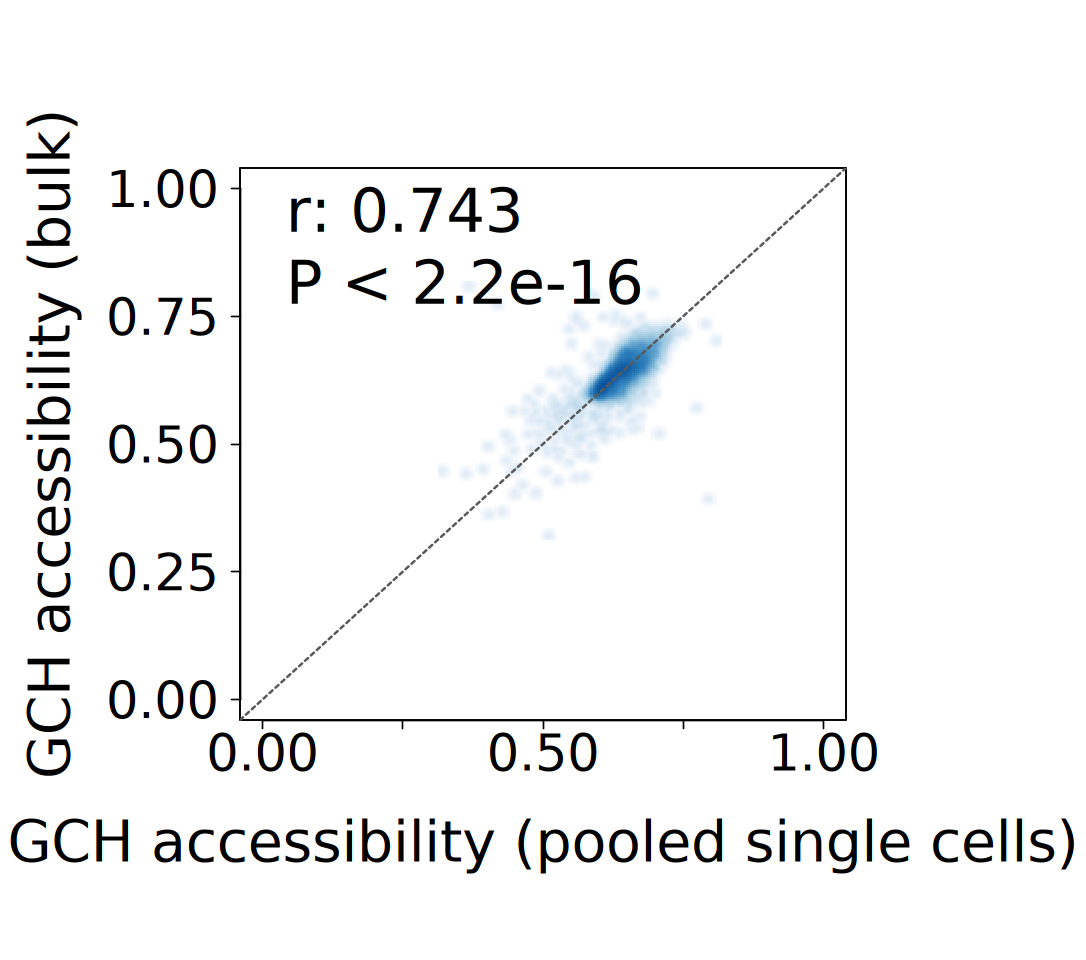

In [64]:
# 250kb GCH accessibility -- QUANTILE-NORMALIZED. Reuses `m` (250kb bins) from the
# previous cell. Same inline large-font format.
stopifnot(exists("m"))
quantile_normalize <- function(matrix_data) {
  n_rows <- nrow(matrix_data); n_cols <- ncol(matrix_data)
  max_non_na <- max(colSums(!is.na(matrix_data)))
  sorted_matrix <- matrix(NA_real_, nrow = max_non_na, ncol = n_cols)
  for (i in seq_len(n_cols)) { v <- matrix_data[, i]; v <- sort(v[!is.na(v)])
    sorted_matrix[seq_along(v), i] <- v }
  row_means <- rowMeans(sorted_matrix, na.rm = TRUE)
  out <- matrix(NA_real_, nrow = n_rows, ncol = n_cols, dimnames = dimnames(matrix_data))
  for (i in seq_len(n_cols)) { v <- matrix_data[, i]; na <- is.na(v)
    out[!na, i] <- row_means[rank(v[!na], ties.method = "average")] }
  out
}
qn <- quantile_normalize(as.matrix(as.data.frame(m)[, c("pseudobulk", "bulk")]))
x <- qn[, 1]; y <- qn[, 2]
r_p <- cor(x, y, use = "complete.obs")
r_s <- cor(x, y, method = "spearman", use = "complete.obs")
cat(sprintf("GCH 250kb QN   n = %s   Pearson r = %.3f   Spearman rho = %.3f\n",
            format(length(x), big.mark = ","), r_p, r_s))

stat_choice <- "pearson"   # annotation: "pearson" or "spearman"
annot <- if (stat_choice == "spearman") sprintf("rho: %.3f\nP < 2.2e-16", r_s) else sprintf("r: %.3f\nP < 2.2e-16", r_p)

bpalette <- colorRampPalette(c("white", "#deebf7", "#9ecae1", "#3182bd", "#08519c"))
draw_one <- function() {
  par(mar = c(10, 10, 7, 10), mgp = c(6, 1.2, 0),
      cex.lab = 2.5, cex.axis = 2.5, family = "sans", tcl = -0.35, las = 1)
  smoothScatter(x, y, xlim = c(0, 1), ylim = c(0, 1), nrpoints = 0,
                xlab = "", ylab = "", main = "", colramp = bpalette, axes = FALSE)
  axis(1, at = seq(0, 1, by = 0.25), lwd = 1, mgp = c(3, 1.2, 0))
  axis(2, at = seq(0, 1, by = 0.25), lwd = 1, las = 1, mgp = c(3.5, 0.9, 0))
  mtext("GCH accessibility (pooled single cells)", side = 1, line = 5.0, cex = 2.8)
  mtext("GCH accessibility (bulk)",                side = 2, line = 7,   cex = 2.8, las = 0)
  box(lwd = 1)
  abline(0, 1, lty = 2, lwd = 1.5, col = "grey35")
  text(0.02, 0.85, annot, pos = 4, cex = 3, font = 2)
}
out_pdf <- file.path(FIGDIR, "newbulk_acc_250kb_GCH_quantileNorm.pdf")
fig_w <- 9.05; fig_h <- 8
pdf(out_pdf, width = fig_w, height = fig_h, useDingbats = FALSE, family = "Helvetica"); draw_one(); dev.off()
cat("wrote", out_pdf, "\n")
options(repr.plot.width = fig_w, repr.plot.height = fig_h); draw_one()


In [66]:
# COMPUTE (A) -- GCH 250kb QN, BIN-LEVEL blacklist filter.
# Build 250kb bins (each side over its own sites), DROP any bin overlapping an
# ENCODE blacklist region, then quantile-normalize. Heavy; kept SEPARATE from the
# plot so re-styling the figure does not recompute. Produces df_binBL.
stopifnot(exists("m_gch"))
BLACKLIST <- "/gpfs/projects/b1198/epifluidlab/yoshii/reference/hg38/hg38-blacklist.v2.bed"
BIN <- 250000
bl <- fread(BLACKLIST, header = FALSE, select = 1:3, col.names = c("chr","start","end"))
setkey(bl, chr, start, end)

binsA <- m_gch[, .(m_pb = sum(m_pb, na.rm = TRUE), cov_pb = sum(cov_pb, na.rm = TRUE),
                   m_bk = sum(m_bk, na.rm = TRUE), cov_bk = sum(cov_bk, na.rm = TRUE)),
               by = .(chr, bin = start %/% BIN)][cov_pb > 0 & cov_bk > 0]
binsA[, `:=`(start = bin * BIN, end = bin * BIN + BIN - 1L)]   # 0-based bin interval
ovA   <- foverlaps(binsA, bl, by.x = c("chr","start","end"), type = "any",
                   which = TRUE, nomatch = NULL)
keepA <- if (nrow(ovA)) binsA[-unique(ovA$xid)] else binsA
cat(sprintf("bin-level BL: kept %s of %s 250kb bins (dropped %s overlapping blacklist)\n",
            format(nrow(keepA), big.mark = ","), format(nrow(binsA), big.mark = ","),
            format(nrow(binsA) - nrow(keepA), big.mark = ",")))

quantile_normalize <- function(matrix_data) {
  n_rows <- nrow(matrix_data); n_cols <- ncol(matrix_data)
  max_non_na <- max(colSums(!is.na(matrix_data)))
  sorted_matrix <- matrix(NA_real_, nrow = max_non_na, ncol = n_cols)
  for (i in seq_len(n_cols)) { v <- matrix_data[, i]; v <- sort(v[!is.na(v)])
    sorted_matrix[seq_along(v), i] <- v }
  row_means <- rowMeans(sorted_matrix, na.rm = TRUE)
  out <- matrix(NA_real_, nrow = n_rows, ncol = n_cols, dimnames = dimnames(matrix_data))
  for (i in seq_len(n_cols)) { v <- matrix_data[, i]; na <- is.na(v)
    out[!na, i] <- row_means[rank(v[!na], ties.method = "average")] }
  out
}
qnA <- quantile_normalize(as.matrix(data.frame(pseudobulk = keepA$m_pb / keepA$cov_pb,
                                               bulk       = keepA$m_bk / keepA$cov_bk)))
df_binBL <- data.frame(pseudobulk = qnA[, 1], bulk = qnA[, 2])
cat(sprintf("bin-level BL QN: n = %s   Pearson r = %.3f   Spearman rho = %.3f\n",
            format(nrow(df_binBL), big.mark = ","),
            cor(df_binBL$pseudobulk, df_binBL$bulk),
            cor(df_binBL$pseudobulk, df_binBL$bulk, method = "spearman")))


bin-level BL: kept 10,708 of 11,670 250kb bins (dropped 962 overlapping blacklist)
bin-level BL QN: n = 10,708   Pearson r = 0.761   Spearman rho = 0.766


pdf 
  2

wrote /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/gm_sc_new/figures/newbulk_acc_250kb_GCH_quantileNorm_binBlacklist.pdf 


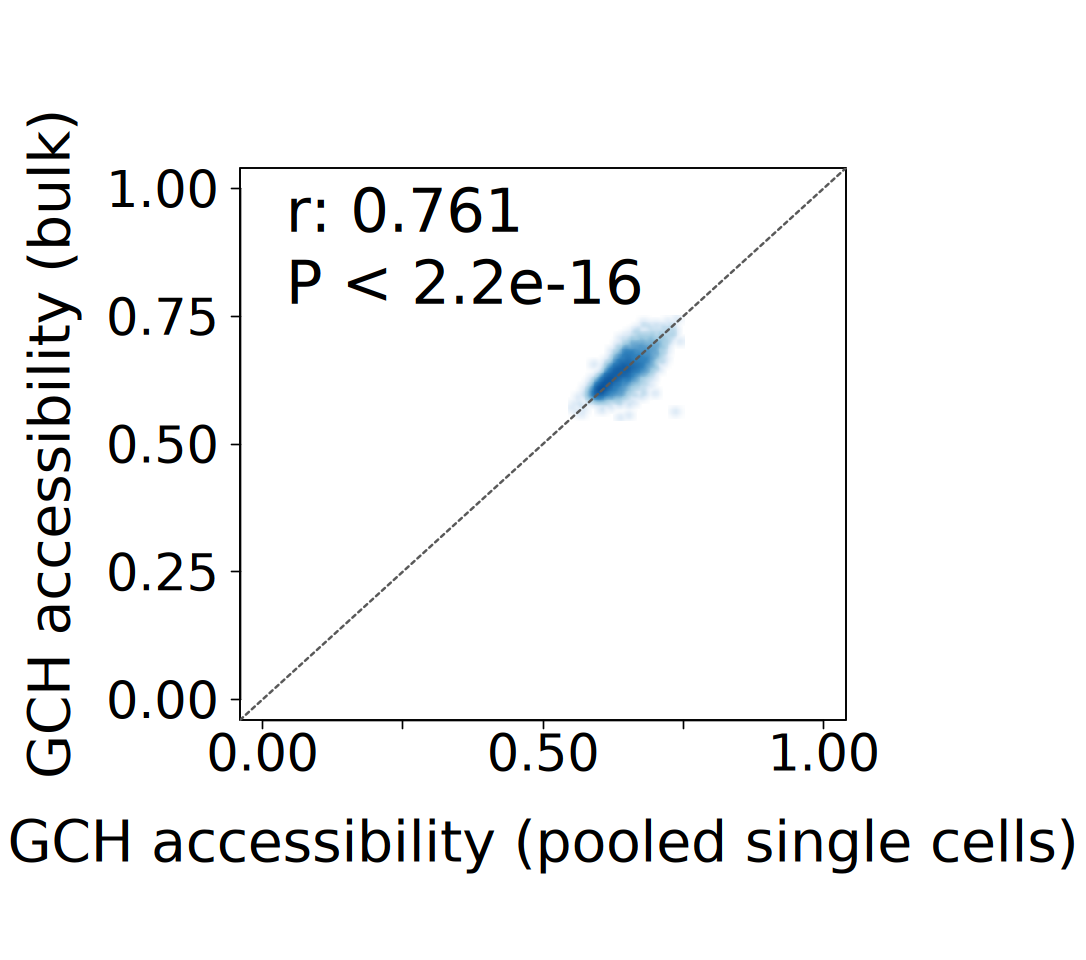

In [67]:
# PLOT (A) -- GCH 250kb QN, BIN-LEVEL blacklist-filtered.  Edit freely -- reuses the precomputed df_binBL (no recompute).
stopifnot(exists("df_binBL"))
x <- df_binBL$pseudobulk; y <- df_binBL$bulk
r_p <- cor(x, y); r_s <- cor(x, y, method = "spearman")
stat_choice <- "pearson"   # annotation: "pearson" or "spearman"
annot <- if (stat_choice == "spearman") sprintf("rho: %.3f\nP < 2.2e-16", r_s) else sprintf("r: %.3f\nP < 2.2e-16", r_p)

bpalette <- colorRampPalette(c("white", "#deebf7", "#9ecae1", "#3182bd", "#08519c"))
draw_one <- function() {
  par(mar = c(10, 10, 7, 10), mgp = c(6, 1.2, 0),
      cex.lab = 2.5, cex.axis = 2.5, family = "sans", tcl = -0.35, las = 1)
  smoothScatter(x, y, xlim = c(0, 1), ylim = c(0, 1), nrpoints = 0,
                xlab = "", ylab = "", main = "", colramp = bpalette, axes = FALSE)
  axis(1, at = seq(0, 1, by = 0.25), lwd = 1, mgp = c(3, 1.2, 0))
  axis(2, at = seq(0, 1, by = 0.25), lwd = 1, las = 1, mgp = c(3.5, 0.9, 0))
  mtext("GCH accessibility (pooled single cells)", side = 1, line = 5.0, cex = 2.8)
  mtext("GCH accessibility (bulk)",                side = 2, line = 7,   cex = 2.8, las = 0)
  box(lwd = 1)
  abline(0, 1, lty = 2, lwd = 1.5, col = "grey35")
  text(0.02, 0.85, annot, pos = 4, cex = 3, font = 2)
}
out_pdf <- file.path(FIGDIR, "newbulk_acc_250kb_GCH_quantileNorm_binBlacklist.pdf")
fig_w <- 9.05; fig_h <- 8
pdf(out_pdf, width = fig_w, height = fig_h, useDingbats = FALSE, family = "Helvetica"); draw_one(); dev.off()
cat("wrote", out_pdf, "\n")
options(repr.plot.width = fig_w, repr.plot.height = fig_h); draw_one()


In [68]:
# COMPUTE (B) -- GCH 250kb QN, LOCUS-LEVEL blacklist filter.
# DROP per-site GpCs overlapping an ENCODE blacklist region FIRST, then build 250kb
# bins + quantile-normalize. Heavy; kept SEPARATE from the plot. Produces df_locusBL.
stopifnot(exists("m_gch"))
BLACKLIST <- "/gpfs/projects/b1198/epifluidlab/yoshii/reference/hg38/hg38-blacklist.v2.bed"
BIN <- 250000
bl <- fread(BLACKLIST, header = FALSE, select = 1:3, col.names = c("chr","start","end"))
setkey(bl, chr, start, end)

ovB   <- foverlaps(m_gch, bl, by.x = c("chr","start","end"), type = "any",
                   which = TRUE, nomatch = NULL)
clean <- if (nrow(ovB)) m_gch[-unique(ovB$xid)] else m_gch
cat(sprintf("locus-level BL: kept %s of %s GpC sites (dropped %s overlapping blacklist)\n",
            format(nrow(clean), big.mark = ","), format(nrow(m_gch), big.mark = ","),
            format(nrow(m_gch) - nrow(clean), big.mark = ",")))

binsB <- clean[, .(m_pb = sum(m_pb, na.rm = TRUE), cov_pb = sum(cov_pb, na.rm = TRUE),
                   m_bk = sum(m_bk, na.rm = TRUE), cov_bk = sum(cov_bk, na.rm = TRUE)),
               by = .(chr, bin = start %/% BIN)][cov_pb > 0 & cov_bk > 0]

quantile_normalize <- function(matrix_data) {
  n_rows <- nrow(matrix_data); n_cols <- ncol(matrix_data)
  max_non_na <- max(colSums(!is.na(matrix_data)))
  sorted_matrix <- matrix(NA_real_, nrow = max_non_na, ncol = n_cols)
  for (i in seq_len(n_cols)) { v <- matrix_data[, i]; v <- sort(v[!is.na(v)])
    sorted_matrix[seq_along(v), i] <- v }
  row_means <- rowMeans(sorted_matrix, na.rm = TRUE)
  out <- matrix(NA_real_, nrow = n_rows, ncol = n_cols, dimnames = dimnames(matrix_data))
  for (i in seq_len(n_cols)) { v <- matrix_data[, i]; na <- is.na(v)
    out[!na, i] <- row_means[rank(v[!na], ties.method = "average")] }
  out
}
qnB <- quantile_normalize(as.matrix(data.frame(pseudobulk = binsB$m_pb / binsB$cov_pb,
                                               bulk       = binsB$m_bk / binsB$cov_bk)))
df_locusBL <- data.frame(pseudobulk = qnB[, 1], bulk = qnB[, 2])
cat(sprintf("locus-level BL QN: n = %s   Pearson r = %.3f   Spearman rho = %.3f\n",
            format(nrow(df_locusBL), big.mark = ","),
            cor(df_locusBL$pseudobulk, df_locusBL$bulk),
            cor(df_locusBL$pseudobulk, df_locusBL$bulk, method = "spearman")))


locus-level BL: kept 216,846,446 of 218,503,111 GpC sites (dropped 1,656,665 overlapping blacklist)
locus-level BL QN: n = 11,366   Pearson r = 0.759   Spearman rho = 0.762


pdf 
  2

wrote /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/gm_sc_new/figures/newbulk_acc_250kb_GCH_quantileNorm_locusBlacklist.pdf 


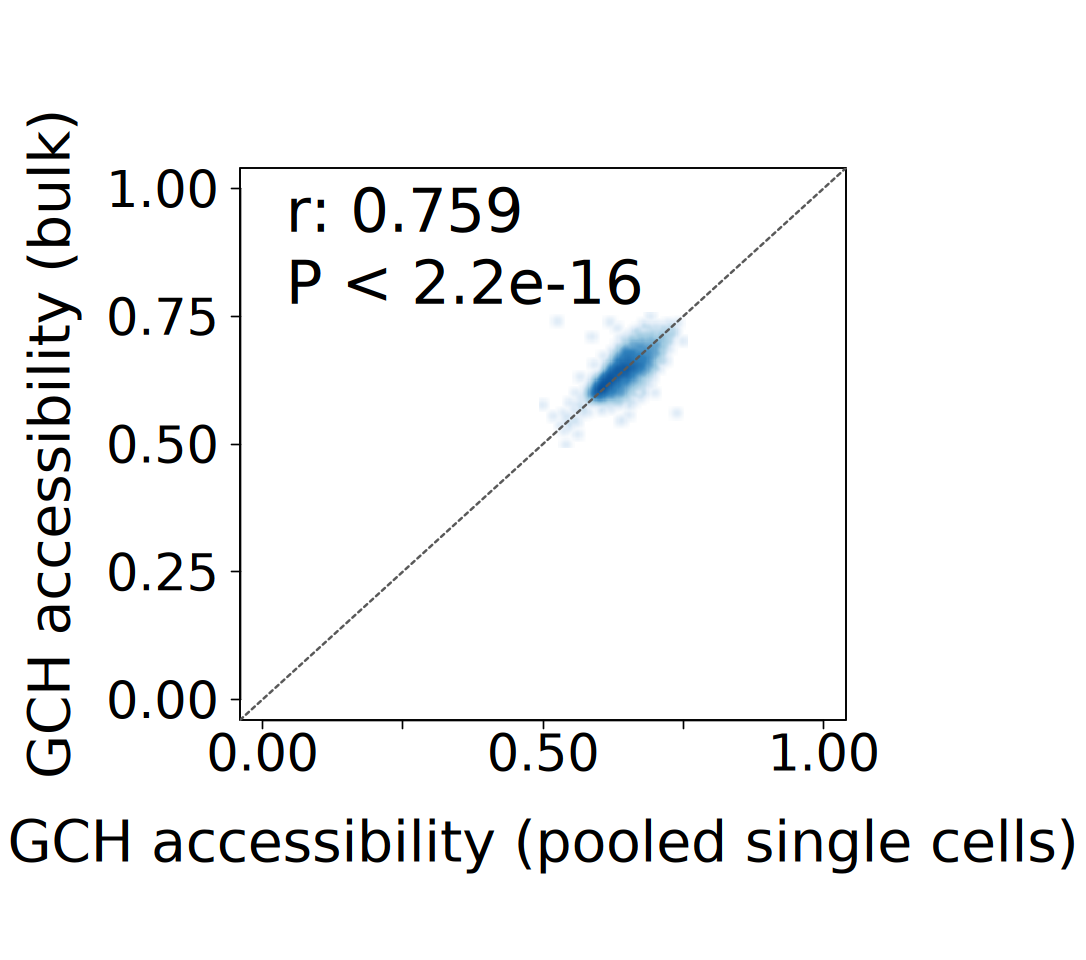

In [69]:
# PLOT (B) -- GCH 250kb QN, LOCUS-LEVEL blacklist-filtered.  Edit freely -- reuses the precomputed df_locusBL (no recompute).
stopifnot(exists("df_locusBL"))
x <- df_locusBL$pseudobulk; y <- df_locusBL$bulk
r_p <- cor(x, y); r_s <- cor(x, y, method = "spearman")
stat_choice <- "pearson"   # annotation: "pearson" or "spearman"
annot <- if (stat_choice == "spearman") sprintf("rho: %.3f\nP < 2.2e-16", r_s) else sprintf("r: %.3f\nP < 2.2e-16", r_p)

bpalette <- colorRampPalette(c("white", "#deebf7", "#9ecae1", "#3182bd", "#08519c"))
draw_one <- function() {
  par(mar = c(10, 10, 7, 10), mgp = c(6, 1.2, 0),
      cex.lab = 2.5, cex.axis = 2.5, family = "sans", tcl = -0.35, las = 1)
  smoothScatter(x, y, xlim = c(0, 1), ylim = c(0, 1), nrpoints = 0,
                xlab = "", ylab = "", main = "", colramp = bpalette, axes = FALSE)
  axis(1, at = seq(0, 1, by = 0.25), lwd = 1, mgp = c(3, 1.2, 0))
  axis(2, at = seq(0, 1, by = 0.25), lwd = 1, las = 1, mgp = c(3.5, 0.9, 0))
  mtext("GCH accessibility (pooled single cells)", side = 1, line = 5.0, cex = 2.8)
  mtext("GCH accessibility (bulk)",                side = 2, line = 7,   cex = 2.8, las = 0)
  box(lwd = 1)
  abline(0, 1, lty = 2, lwd = 1.5, col = "grey35")
  text(0.02, 0.85, annot, pos = 4, cex = 3, font = 2)
}
out_pdf <- file.path(FIGDIR, "newbulk_acc_250kb_GCH_quantileNorm_locusBlacklist.pdf")
fig_w <- 9.05; fig_h <- 8
pdf(out_pdf, width = fig_w, height = fig_h, useDingbats = FALSE, family = "Helvetica"); draw_one(); dev.off()
cat("wrote", out_pdf, "\n")
options(repr.plot.width = fig_w, repr.plot.height = fig_h); draw_one()
